In [1]:
## Load Data
import pandas as pd
df = pd.read_csv('Prediksi Kurs Rupiah terhadap Dolar.csv')
df

,Kurs Jual,Tanggal
0,15101.13,06/27/2023
1,15072.99,06/26/2023
2,14992.59,06/23/2023
3,15056.91,06/22/2023
4,15115.20,06/21/2023
...,...,...
611,14128.29,01/08/2021
612,14007.69,01/07/2021
613,13995.63,01/06/2021
614,14014.73,01/05/2021


In [2]:
## EDA
print(f'Cek 5 data teratas \n {df.head()} \n')

print(f'Cek tipe data \n {df.dtypes} \n')

print(f'Cek missing values \n {df.isnull().sum()}')

Cek 5 data teratas 
    Kurs Jual     Tanggal
0   15101.13  06/27/2023
1   15072.99  06/26/2023
2   14992.59  06/23/2023
3   15056.91  06/22/2023
4   15115.20  06/21/2023 

Cek tipe data 
 Kurs Jual    float64
Tanggal          str
dtype: object 

Cek missing values 
 Kurs Jual    0
Tanggal      0
dtype: int64


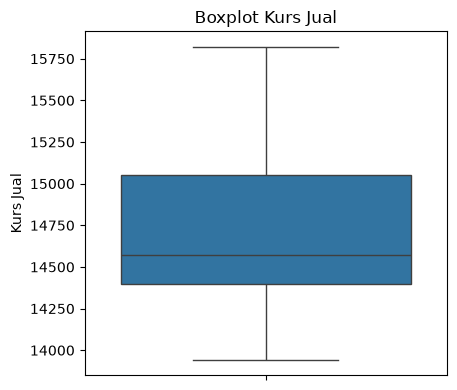

In [3]:
## Outlier
import math
import matplotlib.pyplot as plt
import seaborn as sns

numerical_columns = df.select_dtypes(include='number').columns

## Outlier
n_cols = 4  # jumlah plot per baris, silakan diubah
n_rows = math.ceil(len(numerical_columns) / n_cols)

plt.figure(figsize=(4 * n_cols, 4 * n_rows))

for i, column in enumerate(numerical_columns):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.boxplot(y=df[column])
    plt.title(f'Boxplot {column}')

plt.tight_layout()
plt.show()

In [4]:
# Pilih kolom numerik
numerical_columns = df.select_dtypes(include='number').columns

# Keluarkan kolom ID jika ada
numerical_columns = numerical_columns.drop(
    ['distribution_id'], errors='ignore'
)

# Hitung Q1, Q3, dan IQR
Q1 = df[numerical_columns].quantile(0.25)
Q3 = df[numerical_columns].quantile(0.75)
IQR = Q3 - Q1

# Hitung batas bawah dan atas
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Hitung jumlah outlier
outlier_mask = (
    (df[numerical_columns] < lower_bound) |
    (df[numerical_columns] > upper_bound)
)

# Buat tabel ringkasan
outlier_summary = pd.DataFrame({
    'Q1': Q1,
    'Q3': Q3,
    'IQR': IQR,
    'Lower Bound': lower_bound,
    'Upper Bound': upper_bound,
    'Outlier Count': outlier_mask.sum(),
    'Outlier Percentage': (
        outlier_mask.sum() / len(df) * 100
    )
})

outlier_summary.sort_values(
    by='Outlier Count',
    ascending=False
)

,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
Kurs Jual,14396.3775,15050.3825,654.005,13415.37,16031.39,0,0.0
